In [10]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.lib.distances import distance_array

TOP  = "md_TCBP_0_1.gro"      # структура всей системы с лигандом (33495 атомов)
TRAJ = "600-ns.xtc"     # склеенная траектория
CUT  = 4.5                # Å = 0.45 нм
STEP = 5                  # каждый 5-й кадр

u = mda.Universe(TOP, TRAJ)
print("atoms:", u.atoms.n_atoms, " frames:", len(u.trajectory),
      " the end, ns:", u.trajectory[-1].time / 1000)

pep1 = u.atoms[:256].select_atoms("not name H*")
pep2 = u.atoms[256:512].select_atoms("not name H*")
lig  = u.atoms[512:544].select_atoms("not name H*")
print("heavy atoms:", len(pep1), len(pep2), len(lig))
print("ligand:", u.atoms[512:544].resnames[0])

atoms: 33495  frames: 300001  the end, ns: 600.0
heavy atoms: 139 139 26
ligand: TCB


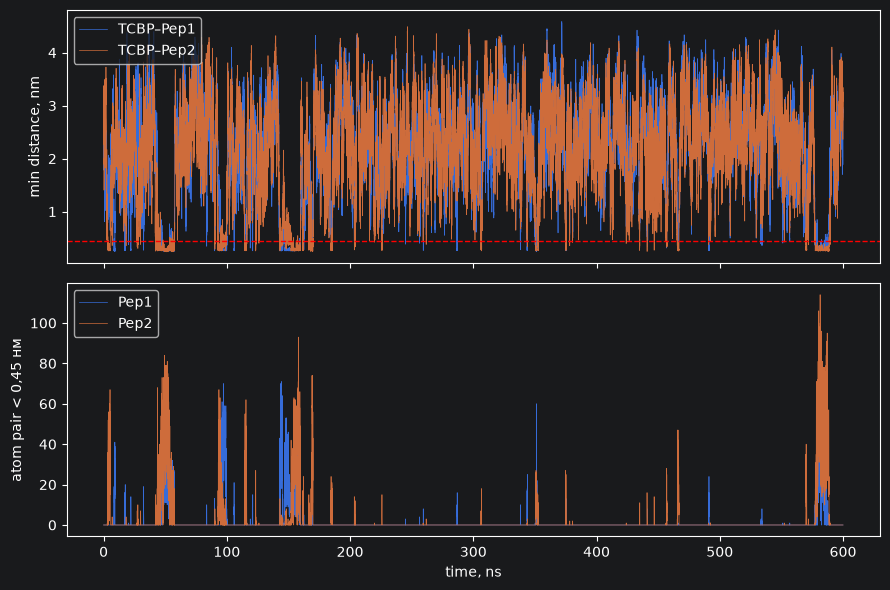

ligand-any peptide contact fraction: 0.11
with Pep1: 0.08, with Pep2: 0.09


In [11]:
t, d1, d2, n1, n2 = [], [], [], [], []
for ts in u.trajectory[::STEP]:
    a = distance_array(lig.positions, pep1.positions, box=ts.dimensions)
    b = distance_array(lig.positions, pep2.positions, box=ts.dimensions)
    t.append(ts.time / 1000)
    d1.append(a.min() / 10); d2.append(b.min() / 10)    # Å -> нм
    n1.append((a < CUT).sum()); n2.append((b < CUT).sum())

t, d1, d2, n1, n2 = map(np.array, (t, d1, d2, n1, n2))

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, d1, lw=0.5, label="TCBP–Pep1")
ax[0].plot(t, d2, lw=0.5, label="TCBP–Pep2")
ax[0].axhline(CUT / 10, color="r", ls="--", lw=1)
ax[0].set_ylabel("min distance, nm"); ax[0].legend()
ax[1].plot(t, n1, lw=0.5, label="Pep1")
ax[1].plot(t, n2, lw=0.5, label="Pep2")
ax[1].set_ylabel("atom pair < 0,45 нм"); ax[1].set_xlabel("time, ns"); ax[1].legend()
fig.tight_layout(); fig.savefig("tcbp_contacts.png", dpi=200); plt.show()

bound = (d1 < CUT/10) | (d2 < CUT/10)
print(f"ligand-any peptide contact fraction: {bound.mean():.2f}")
print(f"with Pep1: {(d1 < CUT/10).mean():.2f}, with Pep2: {(d2 < CUT/10).mean():.2f}")

In [12]:
def dimer_metrics(u, step=STEP, cut=CUT):
    allp1 = u.atoms[:256]                       # все атомы Pep1 (для центра масс)
    allp2 = u.atoms[256:512]
    h1 = allp1.select_atoms("not name H*")      # тяжёлые атомы
    h2 = allp2.select_atoms("not name H*")
    t, dmin, ncont, dcom = [], [], [], []
    for ts in u.trajectory[::step]:
        m = distance_array(h1.positions, h2.positions, box=ts.dimensions)
        c1 = allp1.center_of_mass()[None, :]
        c2 = allp2.center_of_mass()[None, :]
        t.append(ts.time / 1000)
        dmin.append(m.min() / 10)               # нм
        ncont.append((m < cut).sum())
        dcom.append(distance_array(c1, c2, box=ts.dimensions)[0, 0] / 10)
    return tuple(map(np.array, (t, dmin, ncont, dcom)))

t_L, dmin_L, nc_L, dcom_L = dimer_metrics(u)    # система с TCBP

[with TCBP] duration: 600 ns, fraction of contact frames: 0.94
   contact formation events: 51
   longest continuous contact: 555 ns
   permanent contact until end starts at: 45 ns


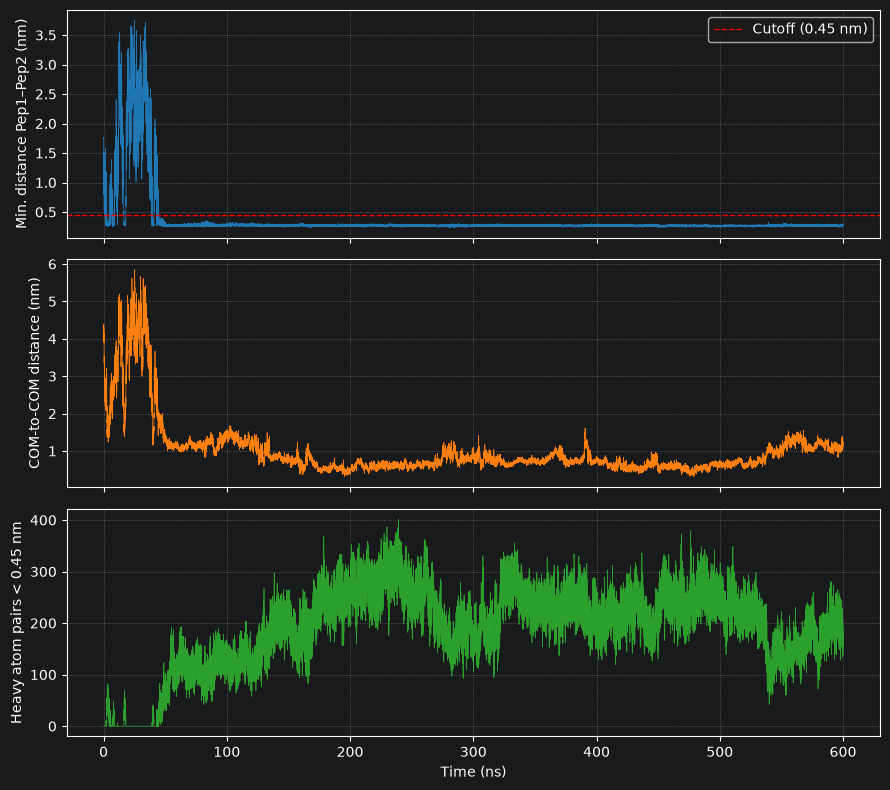

In [13]:
import matplotlib.pyplot as plt
import numpy as np

def longest_run(mask, t):
    best, start = 0.0, None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        if (not v or i == len(mask) - 1) and start is not None:
            end = i if not v else i + 1
            best = max(best, t[end - 1] - t[start])
            start = None
    return best

def report(t, dmin, nc, name):
    contact = dmin < CUT / 10
    no = np.where(~contact)[0]
    print(f"[{name}] duration: {t[-1]:.0f} ns, fraction of contact frames: {contact.mean():.2f}")
    print(f"   contact formation events: {np.sum(np.diff(contact.astype(int)) == 1)}")
    print(f"   longest continuous contact: {longest_run(contact, t):.0f} ns")
    if len(no) and no[-1] + 1 < len(t):
        print(f"   permanent contact until end starts at: {t[no[-1] + 1]:.0f} ns")
    elif len(no) == 0:
        print("   contact maintained across all frames")
    else:
        print("   no contact at the end of the trajectory")

# Run the summary report
report(t_L, dmin_L, nc_L, "with TCBP")

# --- Plotting Grid ---
fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)

# 1. Minimum Atom-to-Atom Distance
ax[0].plot(t_L, dmin_L, lw=0.5, color="#1f77b4")
ax[0].axhline(CUT/10, color="r", ls="--", lw=1, label="Cutoff (0.45 nm)")
ax[0].set_ylabel("Min. distance Pep1–Pep2 (nm)")
ax[0].legend(loc="upper right")
ax[0].grid(True, linestyle=":", alpha=0.6)

# 2. Center-of-Mass Distance
ax[1].plot(t_L, dcom_L, lw=0.5, color="#ff7f0e")
ax[1].set_ylabel("COM-to-COM distance (nm)")
ax[1].grid(True, linestyle=":", alpha=0.6)

# 3. Number of Heavy Atom Contacts
ax[2].plot(t_L, nc_L, lw=0.5, color="#2ca02c")
ax[2].set_ylabel("Heavy atom pairs < 0.45 nm")
ax[2].set_xlabel("Time (ns)")
ax[2].grid(True, linestyle=":", alpha=0.6)

fig.tight_layout()
fig.savefig("dimer_with_TCBP.png", dpi=200)
plt.show()

[without TCBP] duration: 500 ns, fraction of contact frames: 0.61
   contact formation events: 128
   longest continuous contact: 276 ns
   permanent contact until end starts at: 224 ns
[with TCBP] duration: 600 ns, fraction of contact frames: 0.94
   contact formation events: 51
   longest continuous contact: 555 ns
   permanent contact until end starts at: 45 ns


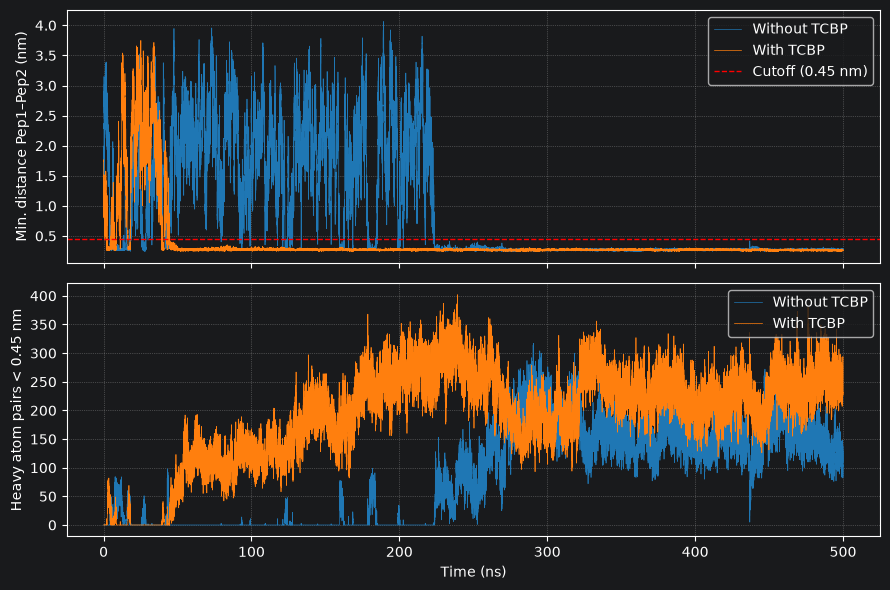

In [16]:
# --- Load Control System (Without Ligand) ---
TOP0  = "/home/magnetic/vkosh/MD data/Амелоидный пептид/два пептида при pH = 7 ff amber99/md_amber_0_1.gro"
TRAJ0 = "/home/magnetic/vkosh/MD data/Амелоидный пептид/два пептида при pH = 7 ff amber99/500ns.xtc"

u0 = mda.Universe(TOP0, TRAJ0)
t_0, dmin_0, nc_0, dcom_0 = dimer_metrics(u0)

# --- Print English Reports ---
report(t_0, dmin_0, nc_0, "without TCBP")
report(t_L, dmin_L, nc_L, "with TCBP")

# --- Comparative Plotting (0–500 ns) ---
w = t_L <= 500
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

# 1. Minimum Distance Comparison
ax[0].plot(t_0, dmin_0, lw=0.5, label="Without TCBP", color="#1f77b4")
ax[0].plot(t_L[w], dmin_L[w], lw=0.5, label="With TCBP", color="#ff7f0e")
ax[0].axhline(CUT/10, color="r", ls="--", lw=1, label="Cutoff (0.45 nm)")
ax[0].set_ylabel("Min. distance Pep1–Pep2 (nm)")
ax[0].legend(loc="upper right")
ax[0].grid(True, linestyle=":", alpha=0.6)

# 2. Heavy Atom Contacts Comparison
ax[1].plot(t_0, nc_0, lw=0.5, label="Without TCBP", color="#1f77b4")
ax[1].plot(t_L[w], nc_L[w], lw=0.5, label="With TCBP", color="#ff7f0e")
ax[1].set_ylabel("Heavy atom pairs < 0.45 nm")
ax[1].set_xlabel("Time (ns)")
ax[1].legend(loc="upper right")
ax[1].grid(True, linestyle=":", alpha=0.6)

fig.tight_layout()
fig.savefig("dimer_compare.png", dpi=200)
plt.show()